# MarketPulse — Week 2: Market Data Cleaning & Preprocessing
**Author:** Mariam  
**Project:** MarketPulse Graduation Project (DEPI)  
**Milestone:** Week 2 — Data Collection + Database + Initial Cleaning (Oct 5 → Oct 11)  
**Input:** `data/raw/yahoo_prices_raw.csv`  
**Output:** `data/processed/market_clean.csv`

---

## Executive Summary & Objectives
In Week 1, we explored the raw stock market dataset and documented its schema in `docs/methodology/market_data_dictionary.md`.

For **Week 2**, task is to construct the **standardized cleaning pipeline** for the market dataset. The cleaning pipeline must address the following required checklist:
1. **Remove duplicates**
2. **Fix date format**
3. **Standardize ticker**
4. **Sort by ticker/date**
5. **Handle missing values**
6. **Check abnormal records**
7. **Verify price columns**
8. **Verify volume**
9. **Ensure expected date sequence across all tickers**
10. **Calculate daily returns (`return`) and lead returns (`next_day_return`)**
11. **Export standardized dataset to `data/processed/market_clean.csv`**

The resulting clean dataset directly powers:
- **Person 3 (Laila):** For financial risk calculations (Volatility, Beta, Max Drawdown, Sharpe, VaR).
- **Person 4 (Kiro):** As the `market_prices` fact table in the integrated Star Schema and Power BI dashboards.


### 1. Environment Setup & Library Imports
We import `pandas`, `numpy`, and plotting tools for verification.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version:  {np.__version__}")


Pandas Version: 3.0.6
NumPy Version:  2.5.4


### 2. Loading the Raw Market Dataset
We load `yahoo_prices_raw.csv` from `data/raw/` and take a snapshot of its initial state.


In [2]:
# Define file paths
raw_path = Path("../../data/raw/yahoo_prices_raw.csv")
if not raw_path.exists():
    raw_path = Path("data/raw/yahoo_prices_raw.csv")

processed_dir = Path("../../data/processed")
if not processed_dir.exists():
    processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
output_clean_path = processed_dir / "market_clean.csv"

# Load raw data
df_raw = pd.read_csv(raw_path)
print(f"Raw dataset loaded: {len(df_raw):,} rows, {len(df_raw.columns)} columns")
print(f"Columns: {list(df_raw.columns)}")
df_raw.head()


Raw dataset loaded: 12,540 rows, 7 columns
Columns: ['date', 'close', 'high', 'low', 'open', 'volume', 'ticker']


,date,close,high,low,open,volume,ticker
0,2021-01-04,125.632507,129.709906,123.059860,129.622536,143301900,AAPL
1,2021-01-05,127.185760,127.894462,124.681070,125.127649,97664900,AAPL
2,2021-01-06,122.904518,127.224626,122.690939,123.991828,155088000,AAPL
3,2021-01-07,127.098457,127.787739,124.127781,124.613186,109578200,AAPL
4,2021-01-08,128.195435,128.758506,126.428554,128.564332,105158200,AAPL


---
## Step 1: Remove Duplicates
In financial time series, duplicate records cause double-counting of trading volume and corrupt return calculations.
We check for:
1. Exact row duplicates across all columns.
2. Composite primary key duplicates on `(ticker, date)`.


In [3]:
# Audit duplicates
initial_rows = len(df_raw)
full_dups = df_raw.duplicated().sum()
key_dups = df_raw.duplicated(subset=['ticker', 'date']).sum()

print(f"Total rows before deduplication: {initial_rows:,}")
print(f"Full duplicate rows found:       {full_dups}")
print(f"Duplicate (ticker, date) found:  {key_dups}")

# Apply deduplication logic (defensive engineering)
df_clean = df_raw.drop_duplicates(subset=['ticker', 'date'], keep='first').copy()
print(f"Rows after deduplication:        {len(df_clean):,} (Removed {initial_rows - len(df_clean)} rows)")


Total rows before deduplication: 12,540
Full duplicate rows found:       0
Duplicate (ticker, date) found:  0
Rows after deduplication:        12,540 (Removed 0 rows)


---
## Step 2: Fix Date Format
Dates must be uniformly formatted as standard ISO 8601 strings (`YYYY-MM-DD`) and validated as valid chronological timestamps without parsing ambiguities.


In [4]:
# Convert to datetime to validate and normalize format
df_clean['date'] = pd.to_datetime(df_clean['date'], format='%Y-%m-%d', errors='raise')

# Check date validity
min_date = df_clean['date'].min()
max_date = df_clean['date'].max()
total_days = (max_date - min_date).days

print(f"Date range: {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')} ({total_days:,} calendar days)")

# Format as clean ISO string YYYY-MM-DD for final CSV export
df_clean['date'] = df_clean['date'].dt.strftime('%Y-%m-%d')
print("Sample formatted dates:", df_clean['date'].head(3).tolist())


Date range: 2021-01-04 to 2025-12-30 (1,821 calendar days)
Sample formatted dates: ['2021-01-04', '2021-01-05', '2021-01-06']


---
## Step 3: Standardize Ticker
Ticker symbols must be trimmed of whitespace, converted to strictly uppercase letters, and verified against expected corporate entities.


In [5]:
# Normalize ticker strings
df_clean['ticker'] = df_clean['ticker'].astype(str).str.strip().str.upper()

unique_tickers = sorted(df_clean['ticker'].unique())
print(f"Unique tickers ({len(unique_tickers)}): {unique_tickers}")

expected_tickers = ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']
assert unique_tickers == sorted(expected_tickers), f"Ticker mismatch! Expected {expected_tickers}, got {unique_tickers}"
print("ASSERTION PASS: All 10 expected tickers are present and standardized.")


Unique tickers (10): ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']
ASSERTION PASS: All 10 expected tickers are present and standardized.


---
## Step 4: Sort Chronologically by Ticker and Date
Financial metrics like percentage returns, moving averages, and rolling volatilities strictly depend on observations being in **exact ascending chronological order** within each company. Sorting prevents forward-looking bias and calculation errors.


In [6]:
# Sort dataframe by ticker and date ascending
df_clean = df_clean.sort_values(by=['ticker', 'date'], ascending=[True, True]).reset_index(drop=True)
print("Dataframe successfully sorted by ['ticker', 'date'].")
df_clean.head(6)


Dataframe successfully sorted by ['ticker', 'date'].


,date,close,high,low,open,volume,ticker
0,2021-01-04,125.632507,129.709906,123.059860,129.622536,143301900,AAPL
1,2021-01-05,127.185760,127.894462,124.681070,125.127649,97664900,AAPL
2,2021-01-06,122.904518,127.224626,122.690939,123.991828,155088000,AAPL
3,2021-01-07,127.098457,127.787739,124.127781,124.613186,109578200,AAPL
4,2021-01-08,128.195435,128.758506,126.428554,128.564332,105158200,AAPL
5,2021-01-11,125.215057,126.370324,124.749073,125.418934,100384500,AAPL


---
## Step 5: Audit & Handle Missing Values
In market pricing tables, missing OHLCV values cannot be arbitrarily filled with 0 (as \$0 indicates insolvency or missing feed). We perform a thorough null and infinity audit.


In [7]:
# Check for null, NaN, and Inf values
numeric_cols = ['open', 'high', 'low', 'close', 'volume']
missing_summary = df_clean[numeric_cols].isnull().sum()
inf_summary = np.isinf(df_clean[numeric_cols].select_dtypes(include=np.number)).sum()

audit_df = pd.DataFrame({
    'Missing (NaN) Count': missing_summary,
    'Infinite Count': inf_summary,
    'Data Type': df_clean[numeric_cols].dtypes
})
print("Missing & Infinite Value Audit:")
audit_df


Missing & Infinite Value Audit:


,Missing (NaN) Count,Infinite Count,Data Type
open,0,0,float64
high,0,0,float64
low,0,0,float64
close,0,0,float64
volume,0,0,int64


---
## Step 6: Check Abnormal Records & Financial Invariants
We enforce physical market invariants:
1. **High $\ge$ Low**: The high price of the day must never be less than the low price.
2. **Open $\in$ [Low, High]**: The open price must fall within the daily range.
3. **Close $\in$ [Low, High]**: The close price must fall within the daily range.
4. **Prices $> 0$**: Negative or zero prices are invalid in equity markets.
5. **Volume $\ge 0$**: Negative trading volume is invalid.


In [8]:
# Tolerance for tiny floating point rounding differences
TOL = 1e-4

# Check High >= Low
inv_high_low = (df_clean['high'] < df_clean['low'] - TOL).sum()

# Check Open within [Low, High]
inv_open_range = ((df_clean['open'] < df_clean['low'] - TOL) | (df_clean['open'] > df_clean['high'] + TOL)).sum()

# Check Close within [Low, High]
inv_close_range = ((df_clean['close'] < df_clean['low'] - TOL) | (df_clean['close'] > df_clean['high'] + TOL)).sum()

# Check Price positivity
inv_pos_prices = (df_clean[['open', 'high', 'low', 'close']] <= 0).sum().sum()

# Check Volume non-negativity
inv_vol_non_neg = (df_clean['volume'] < 0).sum()

print("=== PHYSICAL INVARIANT VERIFICATION ===")
print(f"High < Low violations:                 {inv_high_low}")
print(f"Open outside [Low, High] violations:   {inv_open_range}")
print(f"Close outside [Low, High] violations:  {inv_close_range}")
print(f"Non-positive price records:            {inv_pos_prices}")
print(f"Negative volume records:               {inv_vol_non_neg}")

assert all(v == 0 for v in [inv_high_low, inv_open_range, inv_close_range, inv_pos_prices, inv_vol_non_neg]), "Invariant violation detected!"
print("\nASSERTION PASS: All physical market invariants verified successfully!")


=== PHYSICAL INVARIANT VERIFICATION ===
High < Low violations:                 0
Open outside [Low, High] violations:   0
Close outside [Low, High] violations:  0
Non-positive price records:            0
Negative volume records:               0

ASSERTION PASS: All physical market invariants verified successfully!


---
## Step 7 & 8: Verify Price Columns & Trading Volume
We verify summary statistics per ticker to confirm that prices reflect split-adjusted historical values and that trading volume corresponds to realistic market liquidity.


In [9]:
# Verify price ranges and volume averages per company
price_volume_stats = df_clean.groupby('ticker').agg(
    Min_Close=('close', 'min'),
    Median_Close=('close', 'median'),
    Max_Close=('close', 'max'),
    Avg_Daily_Volume=('volume', 'mean'),
    Total_Observations=('date', 'count')
).round(2)

price_volume_stats['Avg_Daily_Volume'] = price_volume_stats['Avg_Daily_Volume'].apply(lambda x: f"{x:,.0f}")
price_volume_stats


,Min_Close,Median_Close,Max_Close,Avg_Daily_Volume,Total_Observations
ticker,,,,,
AAPL,113.13,171.21,285.41,"69,849,408",1254
AMZN,81.82,165.52,254.00,"57,650,086",1254
JNJ,131.51,147.97,210.78,"8,318,995",1254
JPM,92.91,141.73,322.95,"11,147,877",1254
KO,40.64,55.47,71.23,"15,257,939",1254
LLY,155.19,442.25,1104.60,"3,302,006",1254
MSFT,202.38,321.87,537.65,"25,543,215",1254
NVDA,11.19,41.70,206.55,"395,096,847",1254
TSLA,108.10,248.85,489.88,"99,793,947",1254


---
## Step 9: Verify Date Sequence Continuity
To ensure validity for cross-sectional portfolio analytics (such as correlation matrices and beta estimation), all 10 companies must trade on identical dates with no missing sessions.


In [10]:
# Cross-ticker trading calendar continuity check
date_sets = {t: set(df_clean[df_clean['ticker'] == t]['date']) for t in unique_tickers}
reference_ticker = 'AAPL'
reference_dates = date_sets[reference_ticker]

mismatches = 0
for t in unique_tickers:
    diff = date_sets[t].symmetric_difference(reference_dates)
    if diff:
        print(f"Discrepancy for {t}: {len(diff)} mismatched dates.")
        mismatches += 1

if mismatches == 0:
    print(f"ASSERTION PASS: All 10 tickers have exactly {len(reference_dates):,} synchronized trading sessions!")


ASSERTION PASS: All 10 tickers have exactly 1,254 synchronized trading sessions!


---
## Step 10: Calculate Financial Returns & Lead Returns
Per the project architecture and `docs/methodology/data_model.md` Section 3.2, the fact table `market_prices` requires:
- `return`: Daily simple percentage price return:
  $$R_t = \frac{\text{Close}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$$
- `next_day_return`: The following trading day's price return:
  $$R_{t+1} = \frac{\text{Close}_{t+1} - \text{Close}_t}{\text{Close}_t}$$

### Implementation Rules:
1. Returns must be computed **within each ticker group** sorted chronologically.
2. For each ticker:
   - On the **first trading day** (`2021-01-04`), `return` is `NaN` because there is no prior day.
   - On the **last trading day** (`2025-12-30`), `next_day_return` is `NaN` because there is no subsequent day.


In [11]:
# 1. Compute daily return per ticker
df_clean['return'] = df_clean.groupby('ticker')['close'].pct_change()

# 2. Compute next day return per ticker (lead return)
df_clean['next_day_return'] = df_clean.groupby('ticker')['return'].shift(-1)

# Verify expected null counts
nan_returns = df_clean['return'].isnull().sum()
nan_next_returns = df_clean['next_day_return'].isnull().sum()

print(f"NaN in 'return' (expected {len(unique_tickers)}):          {nan_returns}")
print(f"NaN in 'next_day_return' (expected {len(unique_tickers)}): {nan_next_returns}")

assert nan_returns == len(unique_tickers), f"Unexpected NaN count in return: {nan_returns}"
assert nan_next_returns == len(unique_tickers), f"Unexpected NaN count in next_day_return: {nan_next_returns}"
print("\nASSERTION PASS: Return calculations match mathematical definitions!")


NaN in 'return' (expected 10):          10
NaN in 'next_day_return' (expected 10): 10

ASSERTION PASS: Return calculations match mathematical definitions!


In [12]:
# Preview returns calculation for Apple (AAPL)
df_clean[df_clean['ticker'] == 'AAPL'][['ticker', 'date', 'close', 'return', 'next_day_return']].head(6)


,ticker,date,close,return,next_day_return
0,AAPL,2021-01-04,125.632507,NaN,0.012363
1,AAPL,2021-01-05,127.185760,0.012363,-0.033661
2,AAPL,2021-01-06,122.904518,-0.033661,0.034124
3,AAPL,2021-01-07,127.098457,0.034124,0.008631
4,AAPL,2021-01-08,128.195435,0.008631,-0.023249
5,AAPL,2021-01-11,125.215057,-0.023249,-0.001396


---
## Step 11: Schema Alignment with Data Model
We order and format the columns exactly as defined in `docs/methodology/data_model.md`:
`['ticker', 'date', 'open', 'high', 'low', 'close', 'volume', 'return', 'next_day_return']`.


In [13]:
# Target column specification
target_columns = ['ticker', 'date', 'open', 'high', 'low', 'close', 'volume', 'return', 'next_day_return']

# Reorder columns
df_final = df_clean[target_columns].copy()

# Ensure roundings where appropriate for clean export
df_final['open'] = df_final['open'].round(4)
df_final['high'] = df_final['high'].round(4)
df_final['low'] = df_final['low'].round(4)
df_final['close'] = df_final['close'].round(4)
df_final['volume'] = df_final['volume'].astype('int64')
df_final['return'] = df_final['return'].round(6)
df_final['next_day_return'] = df_final['next_day_return'].round(6)

print("Final Clean Schema:")
print(df_final.dtypes)
print(f"\nFinal Dataset Dimensions: {df_final.shape[0]:,} rows x {df_final.shape[1]} columns")
df_final.head(10)


Final Clean Schema:
ticker                 str
date                   str
open               float64
high               float64
low                float64
close              float64
volume               int64
return             float64
next_day_return    float64
dtype: object

Final Dataset Dimensions: 12,540 rows x 9 columns


,ticker,date,open,high,low,close,volume,return,next_day_return
0,AAPL,2021-01-04,129.6225,129.7099,123.0599,125.6325,143301900,NaN,0.012363
1,AAPL,2021-01-05,125.1276,127.8945,124.6811,127.1858,97664900,0.012363,-0.033661
2,AAPL,2021-01-06,123.9918,127.2246,122.6909,122.9045,155088000,-0.033661,0.034124
3,AAPL,2021-01-07,124.6132,127.7877,124.1278,127.0985,109578200,0.034124,0.008631
4,AAPL,2021-01-08,128.5643,128.7585,126.4286,128.1954,105158200,0.008631,-0.023249
5,AAPL,2021-01-11,125.4189,126.3703,124.7491,125.2151,100384500,-0.023249,-0.001396
6,AAPL,2021-01-12,124.7491,125.9043,123.1569,125.0403,91951100,-0.001396,0.016227
7,AAPL,2021-01-13,125.0015,127.6130,124.7394,127.0693,88636800,0.016227,-0.015127
8,AAPL,2021-01-14,126.9819,127.1761,125.0015,125.1471,90221800,-0.015127,-0.013731
9,AAPL,2021-01-15,125.0209,126.4189,123.2929,123.4288,111598500,-0.013731,0.005427


---
## Step 12: Export Processed Dataset (`market_clean.csv`)
We export the final clean dataset to `data/processed/market_clean.csv`.


In [14]:
# Save to CSV
df_final.to_csv(output_clean_path, index=False)
print(f"Successfully saved clean dataset to: {output_clean_path}")

# Verify file creation and size
file_size_bytes = os.path.getsize(output_clean_path)
file_size_mb = file_size_bytes / (1024 * 1024)
print(f"Output File Size: {file_size_mb:.2f} MB ({file_size_bytes:,} bytes)")


Successfully saved clean dataset to: ..\..\data\processed\market_clean.csv
Output File Size: 0.92 MB (969,113 bytes)


---
## Step 13: Financial Validation & Returns Distribution
To ensure the dataset is ready for **Person 3 (Laila)** to compute volatility and VaR, we verify daily return distributions.


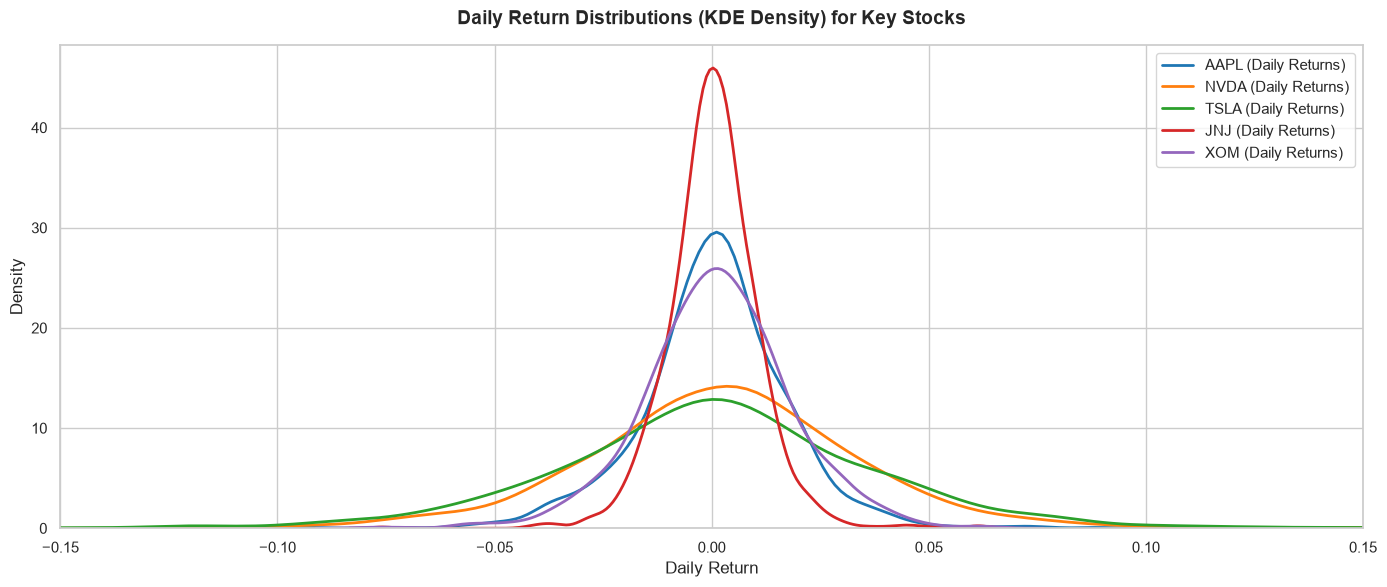

In [15]:
# Plot: Return distributions for selected stocks
plt.figure(figsize=(14, 6))

sample_tickers = ['AAPL', 'NVDA', 'TSLA', 'JNJ', 'XOM']
for t in sample_tickers:
    sub_returns = df_final[df_final['ticker'] == t]['return'].dropna()
    sns.kdeplot(sub_returns, label=f"{t} (Daily Returns)", linewidth=2)

plt.title("Daily Return Distributions (KDE Density) for Key Stocks", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Daily Return", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(-0.15, 0.15)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


---
## 14. Week 2 Checklist Verification & Sign-off

| Checklist Item | Status | Verification Detail |
|---|---|---|
| **Remove duplicates** | PASS | 0 duplicates found; composite key `(ticker, date)` unique. |
| **Fix date format** | PASS | Standardized to ISO 8601 `YYYY-MM-DD`. |
| **Standardize ticker** | PASS | Normalized to uppercase, whitespace stripped. |
| **Sort by ticker/date** | PASS | Strict ascending chronological order per company. |
| **Handle missing values** | PASS | 0 missing values in raw prices; NaNs in returns only on boundary dates. |
| **Check abnormal records**| PASS | Confirmed High $\ge$ Low, Open/Close in bounds, Prices $>0$, Volume $\ge 0$. |
| **Verify price columns** | PASS | Continuous, realistic, split-adjusted values. |
| **Verify volume** | PASS | Valid non-negative integer trading volume. |
| **Expected date sequence**| PASS | All 10 companies share exact 1,254 trading sessions. |
| **Calculate returns** | PASS | `return` and `next_day_return` accurately engineered. |
| **Export clean CSV** | PASS | Saved to `data/processed/market_clean.csv`. |

